# Metric toolbox

`prepare_metric(mesh, arrays)` combines and conditions anisotropic metric fields, with no MMG needed: it **intersects** the metrics of several fields (one mesh resolves them all), **normalises** to a target vertex count, **clamps** the sizes and **grades** the field. A metric asks for edges of unit length measured in it, so each point's request draws as an ellipse with axes `1/sqrt(λ)` along its eigenvectors. See `doc/metric.md`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import EllipseCollection

import meshioplusplus as mp


def ellipses(ax, points, m6, title, every=1, scale=0.2, colour='tab:blue'):
    """Each 2-D metric's unit ball (the x-y block of a 3-D metric), scaled."""
    sel = np.arange(len(points))[::every]
    a, b, c = m6[sel, 0], m6[sel, 1], m6[sel, 2]
    widths, heights, angles = [], [], []
    for aa, bb, cc in zip(a, b, c):
        w, v = np.linalg.eigh([[aa, bb], [bb, cc]])
        widths.append(2 * scale / np.sqrt(w[0])); heights.append(2 * scale / np.sqrt(w[1]))
        angles.append(np.degrees(np.arctan2(v[1, 0], v[0, 0])))
    ax.add_collection(EllipseCollection(widths, heights, angles, units='xy', offsets=points[sel, :2],
                                        offset_transform=ax.transData, facecolor='none', edgecolor=colour, lw=0.6))
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal'); ax.set_title(title)

## Two fronts, one metric

Two fields with a sharp front each, one along `x = 0.5` and one along `y = 0.4`. Each field's Hessian metric (`metric_from_hessian`) asks for small sizes across its own front only; their intersection asks across both, and away from both it stays coarse.

{'complexity_before': 331.98120338075483, 'complexity_after': 331.98120338075483, 'num_graded': 0, 'sweeps': 0}


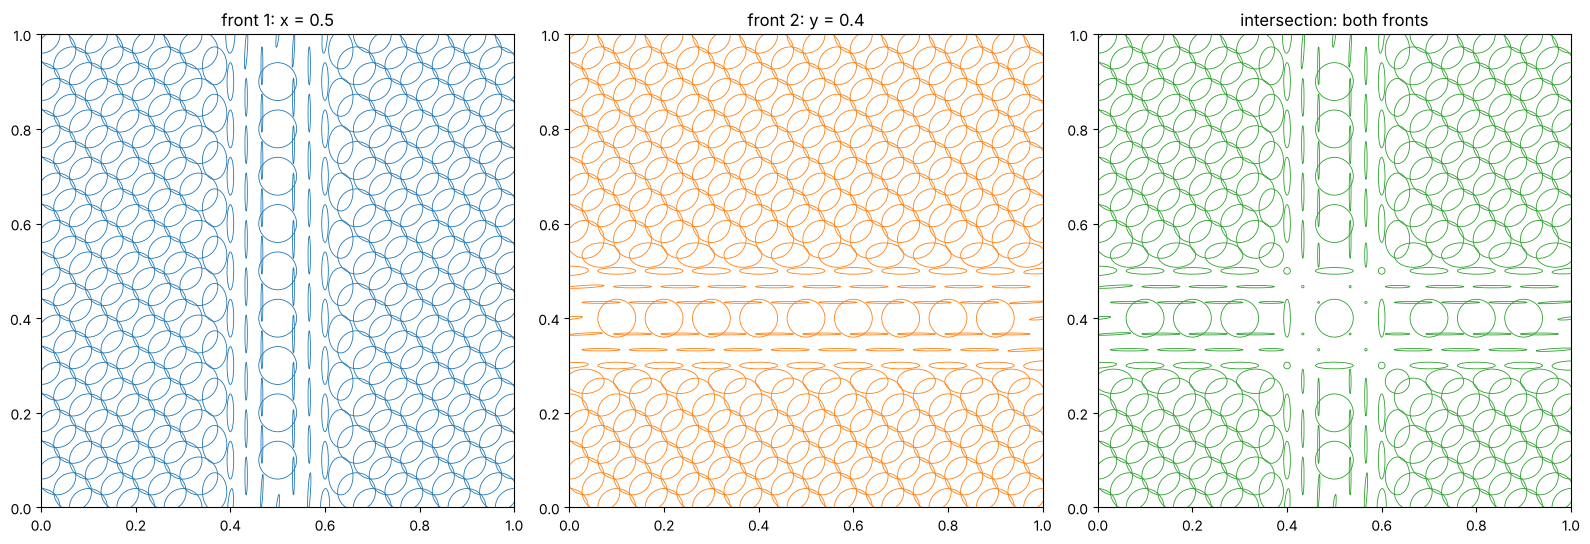

In [2]:
sq = mp.convert_cells(mp.rectangle(dims=(30, 30)), mode='simplexify')
x, y = sq.points[:, 0], sq.points[:, 1]
sq.point_data['u1'] = np.tanh(40 * (x - 0.5))
sq.point_data['u2'] = np.tanh(40 * (y - 0.4))
for name in ('u1', 'u2'):
    sq = mp.hessian(sq, name, location='point')
    sq = mp.metric_from_hessian(sq, f'{name}:hessian', error=1e-2, hmin=1e-3, hmax=0.2, output=f'm_{name}')
both, rep = mp.prepare_metric(sq, ['m_u1', 'm_u2'], output='both', return_report=True)
print(rep)

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
ellipses(axes[0], sq.points, sq.point_data['m_u1'], 'front 1: x = 0.5', every=3)
ellipses(axes[1], sq.points, sq.point_data['m_u2'], 'front 2: y = 0.4', every=3, colour='tab:orange')
ellipses(axes[2], sq.points, both.point_data['both'], 'intersection: both fronts', every=3, colour='tab:green')
plt.tight_layout()
plt.show()

## Normalised, clamped and graded

Normalising spends a vertex budget (here 1 500) where the metric asks for it; clamping bounds the sizes; grading limits how fast sizes grow away from the fronts (here by at most 1.5 per unit length), filling the coarse region with a smooth transition instead of abrupt jumps.

{'complexity_before': 332.0, 'complexity_after': 1447.9, 'num_graded': 0, 'sweeps': 0}
{'complexity_before': 332.0, 'complexity_after': 1795.2, 'num_graded': 402, 'sweeps': 5}


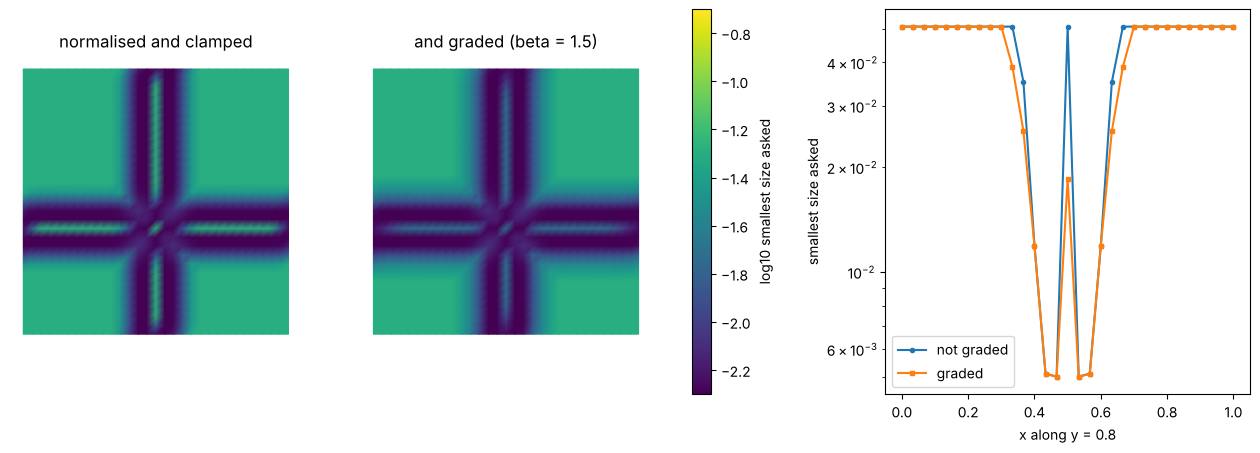

In [3]:
plain, r1 = mp.prepare_metric(sq, ['m_u1', 'm_u2'], target_vertices=1500, hmin=0.005, hmax=0.2, return_report=True)
graded, r2 = mp.prepare_metric(sq, ['m_u1', 'm_u2'], target_vertices=1500, hmin=0.005, hmax=0.2,
                               gradation=1.5, return_report=True)
print({k: round(v, 1) if isinstance(v, float) else v for k, v in r1.items()})
print({k: round(v, 1) if isinstance(v, float) else v for k, v in r2.items()})

def size(m6):
    return 1 / np.sqrt(np.maximum(m6[:, 0], m6[:, 2]))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
tris = sq.cells_dict['triangle']
for ax, m, title in ((axes[0], plain, 'normalised and clamped'), (axes[1], graded, 'and graded (beta = 1.5)')):
    tc = ax.tripcolor(x, y, tris, np.log10(size(m.point_data['metric'])), shading='gouraud', cmap='viridis', vmin=-2.3, vmax=-0.7)
    ax.set_aspect('equal'); ax.set_title(title); ax.axis('off')
plt.colorbar(tc, ax=axes[:2], label='log10 smallest size asked')
row = np.isclose(y, 0.8)
order = np.argsort(x[row])
axes[2].semilogy(x[row][order], size(plain.point_data['metric'])[row][order], 'o-', ms=3, label='not graded')
axes[2].semilogy(x[row][order], size(graded.point_data['metric'])[row][order], 's-', ms=3, label='graded')
axes[2].set_xlabel('x along y = 0.8'); axes[2].set_ylabel('smallest size asked'); axes[2].legend()
plt.show()

## In a pipeline, and on the command line

The step is `PrepareMetric`; the verb `metric` in both CLIs.

In [4]:
_, rep = mp.apply_operations(sq, [{"Op": "PrepareMetric", "Arrays": ["m_u1", "m_u2"], "TargetVertices": 1500, "Gradation": 1.5}])
print(rep['steps'][0])
print('meshioplusplus metric flow.vtu sized.vtu --arrays m_p,m_T --target-vertices 20000 --gradation 1.5 --json')

{'op': 'PrepareMetric', 'ComplexityBefore': 331.98120338075483, 'ComplexityAfter': 1893.3755850477075, 'NumGraded': 404.0}
meshioplusplus metric flow.vtu sized.vtu --arrays m_p,m_T --target-vertices 20000 --gradation 1.5 --json
